# Current-main prepared XYZ timing

Benchmark the current package's prepared path for a full year, with three
warm repeats for each source. Report first-call JAX warm-up, shared retarded
geometry/operator preparation, and warmed waveform evaluation separately.
The notebook benchmarks only the implementation loaded from this checkout.

Use Python 3.12+ and `pip install -e ".[orbits,notebook]"`. Restart the kernel
and run all cells. Detector caches and waveform blocks are released as the
run progresses; no full-year waveform array or data file is saved.

In [1]:
from pathlib import Path
from dataclasses import replace
from time import perf_counter
import hashlib
import importlib.metadata as metadata
import inspect
import json
import os
import platform
import subprocess
import sys

# Load the current checkout, whether launched from its root or notebooks/.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "src/egb_jax_eccentric").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook from the repository or notebooks/ directory")
sys.path.insert(0, str(ROOT / "src"))
os.environ["JAX_PLATFORMS"] = "cpu"
import numpy as np
import jax
jax.config.update("jax_enable_x64", True)

from egb_jax_eccentric import (
    EccentricBinaryParams, LINK_LABELS, default_lisaorbits,
    state_from_lisaorbits, precompute_jax_link_geometry,
    eccentric_links_jax, prepare_xyz_from_links, xyz_from_links,
)
assert Path(inspect.getfile(prepare_xyz_from_links)).is_relative_to(ROOT), (
    "Restart the kernel to load this checkout")

environment = {
    "python": platform.python_version(), "platform": platform.platform(),
    "devices": [str(device) for device in jax.devices()],
    "jax_float64": jax.config.x64_enabled,
    "versions": {name: metadata.version(name) for name in
                 ("numpy", "scipy", "jax", "jaxlib", "pytdi", "lisaorbits")},
    "tdi_source_sha256": hashlib.sha256(
        Path(inspect.getfile(prepare_xyz_from_links)).read_bytes()).hexdigest(),
}
print(json.dumps(environment, indent=2))

def build_cache(times, orbit, measurement_order=3, delay_order=3):
    tick = perf_counter()
    state = state_from_lisaorbits(orbit, times, frame="ecliptic")
    geometry = precompute_jax_link_geometry(state, orbits=orbit, frame="ecliptic")
    delays = {label: geometry["length"][i]
              for i, label in enumerate(LINK_LABELS)}
    geometry_s = perf_counter() - tick
    tick = perf_counter()
    tdi = prepare_xyz_from_links(state, generation=2,
        measurement_order=measurement_order, delay_order=delay_order,
        link_delays=delays)
    tdi_s = perf_counter() - tick
    return state, geometry, delays, tdi, np.array([geometry_s, tdi_s])

def prepared_waveform(source, geometry, tdi):
    # This public wrapper materializes host arrays, synchronizing JAX.
    links = eccentric_links_jax(source, geometry, batch_size=1,
        physics_mode="1pn_periastron", evolution_mode="fixed")
    return tdi(links)

def make_source(frequency_hz=1e-3, eccentricity=.3):
    return EccentricBinaryParams(
        mean_motion=np.pi * frequency_hz, eccentricity=eccentricity,
        m1_solar=.6, m2_solar=.4, distance_m=3.085677581491367e19,
        beta=.2, lambda_=.4, psi=.3, inclination=.8, phi0=.2, fdot=0.,
    )

{
  "python": "3.12.13",
  "platform": "macOS-27.0.1-arm64-arm-64bit",
  "devices": [
    "cpu:0"
  ],
  "jax_float64": true,
  "versions": {
    "numpy": "2.5.3",
    "scipy": "1.18.1",
    "jax": "0.11.2",
    "jaxlib": "0.11.2",
    "pytdi": "2.2.1",
    "lisaorbits": "3.1.0"
  },
  "tdi_source_sha256": "0c5486112037ee219de879e510d34102f663b2c300a02e5a6425b1c9b7166ae4"
}


In [2]:
# Editable workload. Changing cadence/orders also requires reviewing padding.
duration_days, dt = 365.25, 5.
block, halo, repeats = 65536, 128, 3
measurement_order, delay_order = 3, 3
cases = [(1e-3, 0.), (3e-3, .3), (1e-2, .6)]
sources = [make_source(frequency_hz=f, eccentricity=e) for f, e in cases]
samples = int(round(duration_days * 86400 / dt))
blocks = (samples + block - 1) // block
orbit = default_lisaorbits("esa-trailing")

assert measurement_order % 2 == delay_order % 2 == 1
assert halo * dt >= 8 * 12 + 4 * (measurement_order + 1) * dt
benchmark_start = perf_counter()
warm_times = np.arange(-halo, block + halo) * dt
first_state, first_geometry, first_delays, first_tdi, first_setup = build_cache(
    warm_times, orbit, measurement_order, delay_order)
tick = perf_counter()
warm_xyz = prepared_waveform(sources[1], first_geometry, first_tdi)
warmup_s = perf_counter() - tick
assert all(np.isfinite(v).all() for v in warm_xyz.values())
del warm_xyz
print(f"First waveform call (includes JAX compilation): {warmup_s:.3f} s")
print(f"Workload: {blocks} blocks; {samples:,} retained samples/channel; {repeats} repeats/case")

/Users/shubhanshutiwari/Desktop/eGB-multi/.venv-benchmark/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/shubhanshutiwari/Desktop/eGB-multi/.venv-benchmark/lib/python3.12/site-packages/lisaconstants/compat/astropy.py:252: UserWarning: The following constants differ between lisaconstants and the version of astropy you have installed: VACUUM_PERMEABILITY. The recommended version of astropy is 7.2.0. Use a different one at your own risks. 
You may also open an issue at https://gitlab.esa.int/lisa-sgs/commons/lisa-constants to warn that lisaconstants is not compatible with astropy v8.0.1
  warnings.warn(


First waveform call (includes JAX compilation): 0.254 s
Workload: 97 blocks; 6,311,520 retained samples/channel; 3 repeats/case


/Users/shubhanshutiwari/Desktop/eGB-multi/.venv-benchmark/lib/python3.12/site-packages/pytdi/dsp.py:72: ComplexWarning: Casting complex values to real discards the imaginary part
  return data.astype(float)


In [3]:
# Block-first reuse keeps cache memory bounded. Each timed call makes fresh links.
setup = np.zeros(2)
elapsed = np.zeros((len(cases), repeats))
rng = np.random.default_rng(20261014)
jobs = [(case, repeat) for case in range(len(cases)) for repeat in range(repeats)]
checks = []
for block_index, start in enumerate(range(0, samples, block)):
    keep = min(block, samples - start)
    if start == 0:
        state, geometry, delays, tdi, block_setup = (
            first_state, first_geometry, first_delays, first_tdi, first_setup)
        del first_state, first_geometry, first_delays, first_tdi
    else:
        times = (start + np.arange(-halo, block + halo)) * dt
        state, geometry, delays, tdi, block_setup = build_cache(
            times, orbit, measurement_order, delay_order)
    setup += block_setup
    assert max(np.max(values) for values in delays.values()) < 12.
    for job in rng.permutation(len(jobs)):
        case_index, repeat = jobs[job]
        tick = perf_counter()
        xyz = prepared_waveform(sources[case_index], geometry, tdi)
        elapsed[case_index, repeat] += perf_counter() - tick
        assert all(np.isfinite(values).all() for values in xyz.values())
        assert all(len(values[halo:halo + keep]) == keep for values in xyz.values())

    # Selected correctness checks are outside the waveform timing.
    if block_index in (0, blocks - 1):
        for source in sources:
            links = eccentric_links_jax(source, geometry, batch_size=1,
                physics_mode="1pn_periastron", evolution_mode="fixed")
            expected = xyz_from_links(state, links, generation=2,
                measurement_order=measurement_order, delay_order=delay_order,
                link_delays=delays)
            actual = tdi(links)
            for channel in "XYZ":
                np.testing.assert_allclose(actual[channel], expected[channel], rtol=2e-12, atol=1e-30)
            checks.append({"block": block_index, "eccentricity": source.eccentricity,
                "maximum_abs_XYZ_difference": max(float(np.max(abs(actual[ch] - expected[ch]))) for ch in "XYZ")})
        del links, expected, actual
    del state, geometry, delays, tdi, xyz
    if (block_index + 1) % 25 == 0 or block_index + 1 == blocks:
        print(f"Completed {block_index + 1}/{blocks} blocks")

benchmark_wall_s = perf_counter() - benchmark_start
summary = [{"frequency_hz": f, "eccentricity": e,
    "warm_median_s": float(np.median(elapsed[i])),
    "warm_min_s": float(np.min(elapsed[i])), "warm_max_s": float(np.max(elapsed[i])),
    "warm_repeat_s": elapsed[i].tolist()} for i, (f, e) in enumerate(cases)]
print(f"Shared geometry preparation: {setup[0]:.3f} s")
print(f"Shared TDI operator preparation: {setup[1]:.3f} s")
print(f"Shared preparation total: {setup.sum():.3f} s")
print(f"First-call JAX warm-up: {warmup_s:.3f} s")
print(f"Complete benchmark wall time (setup, first call, checks included): {benchmark_wall_s:.3f} s")
print(json.dumps(summary, indent=2))

Completed 25/97 blocks


Completed 50/97 blocks


Completed 75/97 blocks


Completed 97/97 blocks
Shared geometry preparation: 11.949 s
Shared TDI operator preparation: 4.954 s
Shared preparation total: 16.903 s
First-call JAX warm-up: 0.254 s
Complete benchmark wall time (setup, first call, checks included): 53.151 s
[
  {
    "frequency_hz": 0.001,
    "eccentricity": 0.0,
    "warm_median_s": 3.783001790056005,
    "warm_min_s": 3.778700002003461,
    "warm_max_s": 3.7847962453961372,
    "warm_repeat_s": [
      3.778700002003461,
      3.783001790056005,
      3.7847962453961372
    ]
  },
  {
    "frequency_hz": 0.003,
    "eccentricity": 0.3,
    "warm_median_s": 3.9213790837675333,
    "warm_min_s": 3.8763814147096127,
    "warm_max_s": 3.930189877282828,
    "warm_repeat_s": [
      3.930189877282828,
      3.9213790837675333,
      3.8763814147096127
    ]
  },
  {
    "frequency_hz": 0.01,
    "eccentricity": 0.6,
    "warm_median_s": 4.0146767946425825,
    "warm_min_s": 4.005121456924826,
    "warm_max_s": 4.039740410633385,
    "warm_repeat_s": 

| Frequency | Eccentricity | Warm median | Repeat range |
|---|---:|---:|---:|
| 1 mHz | 0 | 3.783 s | 3.779–3.785 s |
| 3 mHz | 0.3 | 3.921 s | 3.876–3.930 s |
| 10 mHz | 0.6 | 4.015 s | 4.005–4.040 s |

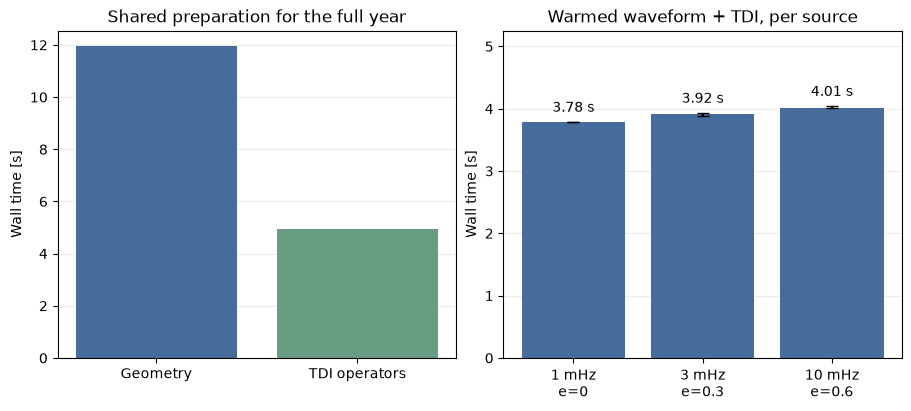

In [4]:
from IPython.display import Markdown, display
import matplotlib.pyplot as plt

table = ["| Frequency | Eccentricity | Warm median | Repeat range |",
         "|---|---:|---:|---:|"]
for row in summary:
    table.append(f"| {row['frequency_hz'] * 1000:g} mHz | {row['eccentricity']:g} | "
                 f"{row['warm_median_s']:.3f} s | {row['warm_min_s']:.3f}–{row['warm_max_s']:.3f} s |")
display(Markdown("\n".join(table)))

fig, axes = plt.subplots(1, 2, figsize=(9, 4), layout="constrained")
axes[0].bar(["Geometry", "TDI operators"], setup, color=["#476C9B", "#689D83"])
axes[0].set_title("Shared preparation for the full year")
median = np.array([row["warm_median_s"] for row in summary])
errors = np.vstack((median - elapsed.min(axis=1), elapsed.max(axis=1) - median))
bars = axes[1].bar(np.arange(len(cases)), median, yerr=errors, capsize=4, color="#476C9B")
axes[1].bar_label(bars, labels=[f"{value:.2f} s" for value in median], padding=5)
axes[1].set_xticks(np.arange(len(cases)), [f"{f * 1000:g} mHz\ne={e:g}" for f, e in cases])
axes[1].set_title("Warmed waveform + TDI, per source")
axes[1].set_ylim(0, elapsed.max() * 1.3)
for axis in axes:
    axis.set_ylabel("Wall time [s]")
    axis.grid(axis="y", alpha=.25)
    axis.set_axisbelow(True)
plt.show()

These are CPU float64 **fixed-evolution** waveforms with 1PN periastron
advance, native ESA-trailing retarded link geometry in ecliptic J2000, and
frequency-unit generation-2 TDI. The same light travel times feed links and
TDI. Geometry/operator caches are independent of source parameters.

The 5 s cadence and interpolation orders 3/3 specify this timing workload;
they are not an accuracy-convergence claim or the full referee fitting-factor
search. No waveform files are saved. Rebuild the cache when the grid, orbit
or interpolation settings change.

Warm medians sum synchronized waveform/link plus TDI call intervals across
every padded block, after the first-call JIT warm-up. They exclude shared
cache preparation, checks, progress printing and output display. Repeat
ranges are observed minima/maxima, not confidence intervals. The first-call
timer includes waveform/TDI work as well as compilation; it is not a pure
compiler timer.

Each block is shared across all cases/repeats before advancing. This does
not imply that an entire annual operator cache fits in RAM, or that an
adaptive full-year likelihood automatically achieves the same reuse. A fresh
single-source traversal also pays preparation. The finite/shape checks cover
all generated blocks; prepared/direct agreement is checked on the first and
last block for all three source cases.